<a href="https://colab.research.google.com/github/Sanjay-H-02/DAV_lab/blob/main/lab6_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [ ]:
data = {
    "Student":['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O'],
  'Study_hours':[2,3,4,5,4,6,5,3,4,5,6,4,5,30,3]
}
df = pd.DataFrame(data)
print("Original DataFrame:")
print(df)

Original DataFrame:
   Student  Study_hours
0        A            2
1        B            3
2        C            4
3        D            5
4        E            4
5        F            6
6        G            5
7        H            3
8        I            4
9        J            5
10       K            6
11       L            4
12       M            5
13       N           30
14       O            3


In [ ]:
from scipy.stats import zscore

In [ ]:
df['Study_hours'].describe()

,Study_hours
count,15.000000
mean,5.933333
std,6.755597
min,2.000000
25%,3.500000
50%,4.000000
75%,5.000000
max,30.000000


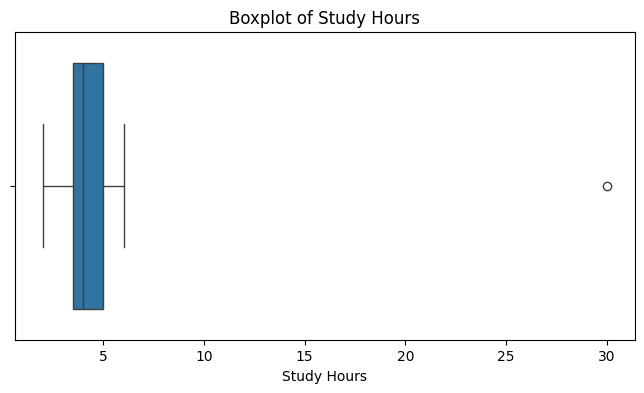

In [ ]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Study_hours'])
plt.title('Boxplot of Study Hours')
plt.xlabel('Study Hours')
plt.show()

In [ ]:
Q1 = df["Study_hours"].quantile(0.25)
Q3 = df["Study_hours"].quantile(0.75)
print("Q1:",Q1)
print("Q3:",Q3)

Q1: 3.5
Q3: 5.0


In [ ]:
IQR = Q3 - Q1
print("IQR:",IQR)

IQR: 1.5


In [ ]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

Lower Bound: 1.25
Upper Bound: 7.25


In [ ]:
outliers = df[(df["Study_hours"] < lower_bound) | (df["Study_hours"] > upper_bound)]
print("Outliers:")
print(outliers)

Outliers:
   Student  Study_hours
13       N           30


In [ ]:
normal_data = df[o(df["Study_hours"] >= lower_bound) & (df["Sudty_hours"] <= upper_bound)]
print("Normal Data:")
display(normal_data)

Normal Data:


,Student,Study_hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5


In [ ]:
df["z_score"] = zscore(df["Study_hours"])
print("Dataset with Z-Scores:")
display(df)

Dataset with Z-Scores:


,Student,Study_hours,z_score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


In [ ]:
z_outliers = df[df["z_score"].abs() > 3]
print("Z-Score Outliers:")
display(z_outliers)

Z-Score Outliers:


,Student,Study_hours,z_score
13,N,30,3.687515


In [ ]:
df_without_outliers = df[(df["z_score"].abs() <= 3)]
print("Dataset without Outliers:")
display(df_without_outliers)

Dataset without Outliers:


,Student,Study_hours,z_score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


In [ ]:
df_capped = df.copy()
df_capped['Study_hours'] = df_capped["Study_hours"].clip(lower_bound, upper_bound)
print("Dataset with Capped Values:")
display(df_capped)

Dataset with Capped Values:


,Student,Study_hours,z_score
0,A,2.00,-0.602669
1,B,3.00,-0.449448
2,C,4.00,-0.296227
3,D,5.00,-0.143006
4,E,4.00,-0.296227
5,F,6.00,0.010215
6,G,5.00,-0.143006
7,H,3.00,-0.449448
8,I,4.00,-0.296227
9,J,5.00,-0.143006


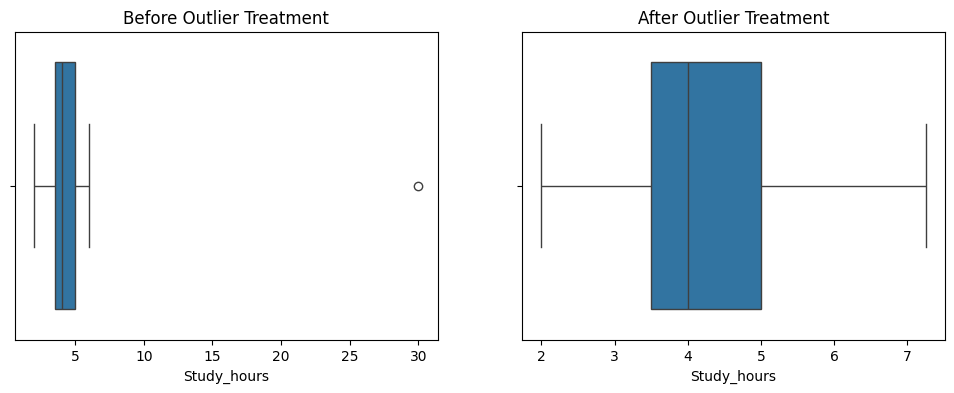

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
sns.boxplot(x=df['Study_hours'])
plt.title('Before Outlier Treatment')

plt.subplot(1,2,2)
sns.boxplot(x=df_capped['Study_hours'])
plt.title('After Outlier Treatment')

plt.show()